Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Missing values:
 RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate rows: 0

Churn rate:
 Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


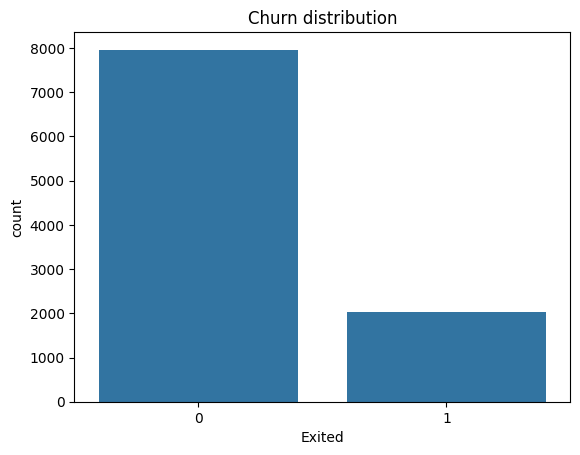


Churn rate by Geography:
Geography
France     0.162
Germany    0.324
Spain      0.167
Name: Exited, dtype: float64

Churn rate by Gender:
Gender
Female    0.251
Male      0.165
Name: Exited, dtype: float64


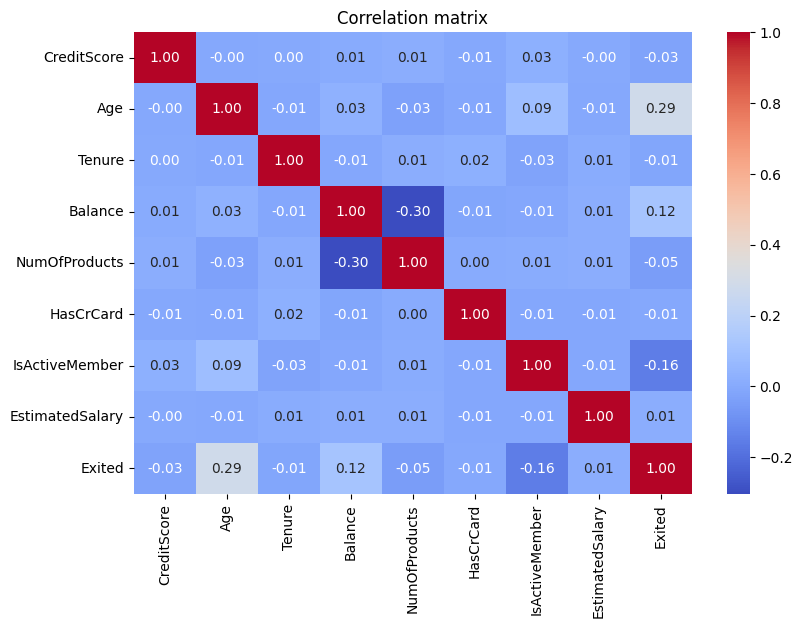

Saved to c:\Users\MSI Thin 15 B12UC\Churn-prediction\data\processed\churn_clean.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Path (works when the notebook runs from notebooks/)
ROOT = Path.cwd().parent
DATA_PATH = ROOT / "data" / "raw" / "Churn_Modelling.csv"

# Load
df = pd.read_csv(DATA_PATH)

# Quick look
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe())

# Data quality
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# Target balance (Exited: 1 = churned, 0 = stayed)
print("\nChurn rate:\n", df["Exited"].value_counts(normalize=True))

sns.countplot(x="Exited", data=df)
plt.title("Churn distribution")
plt.show()

# Drop useless ID columns
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"])

# Churn by category
for col in ["Geography", "Gender"]:
    print(f"\nChurn rate by {col}:")
    print(df.groupby(col)["Exited"].mean().round(3))

# Correlation heatmap (numeric only)
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

# Save a cleaned copy for the next step
out_path = ROOT / "data" / "processed" / "churn_clean.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(out_path, index=False)
print("Saved to", out_path)

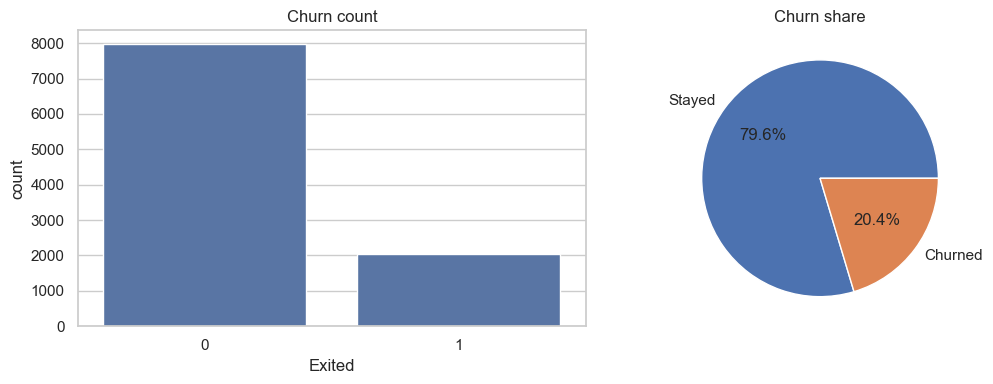

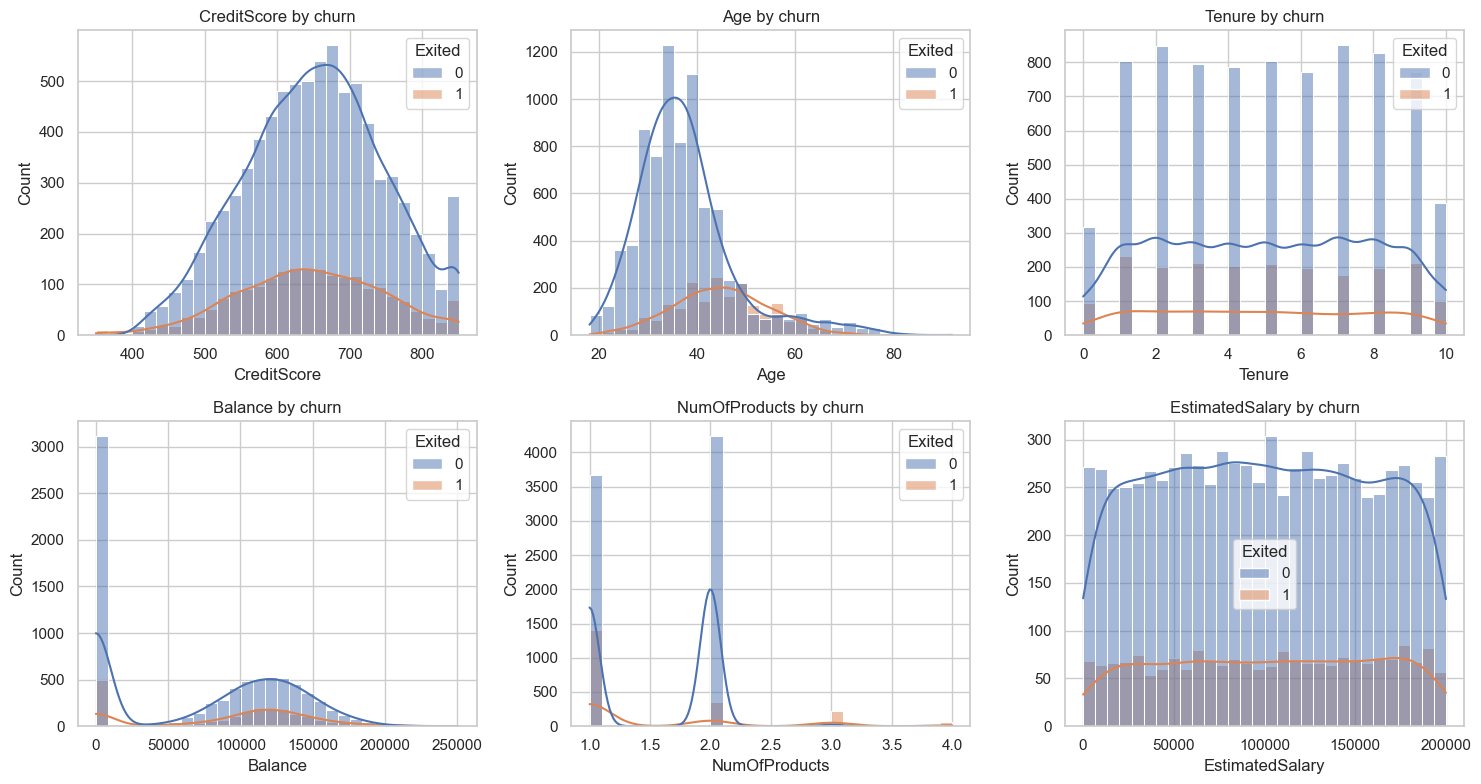

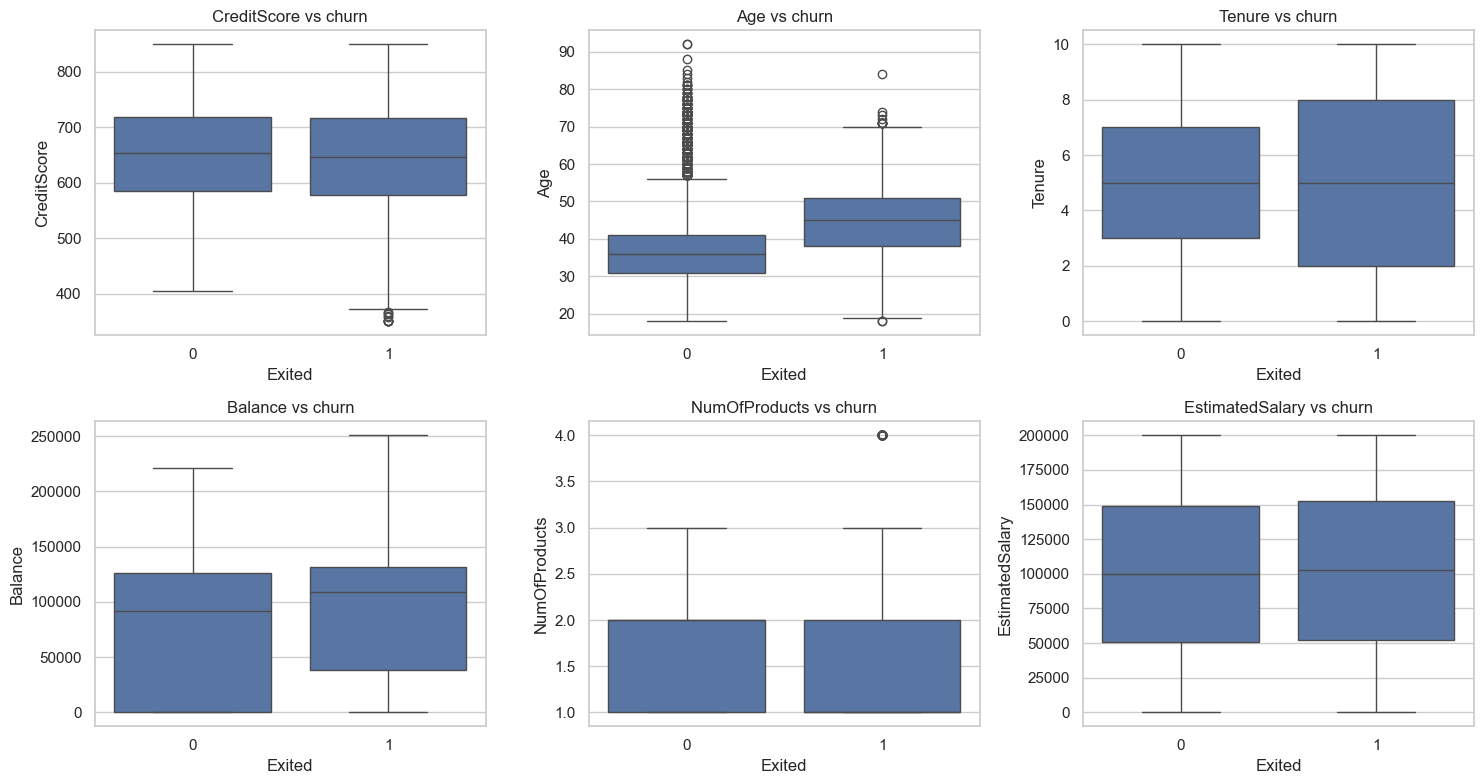

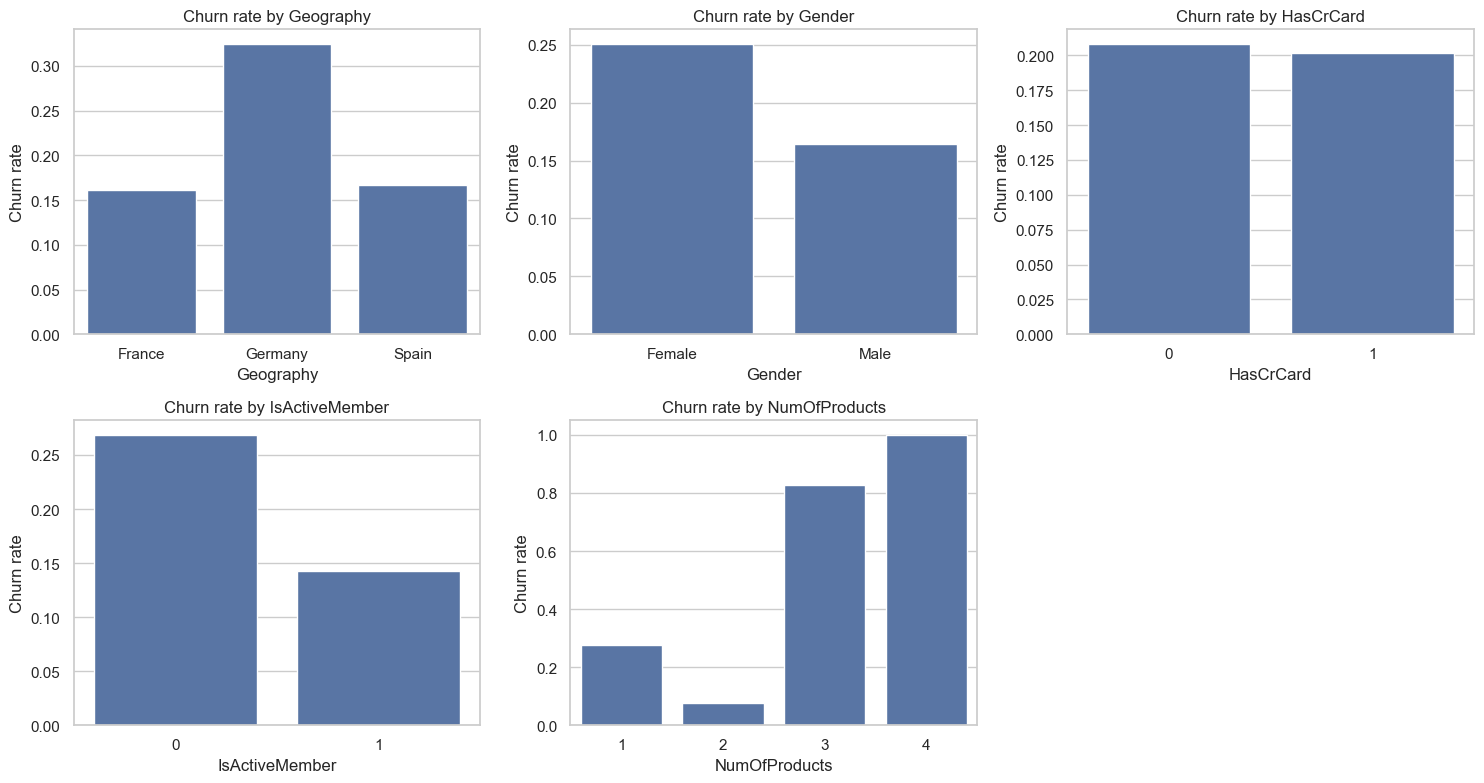

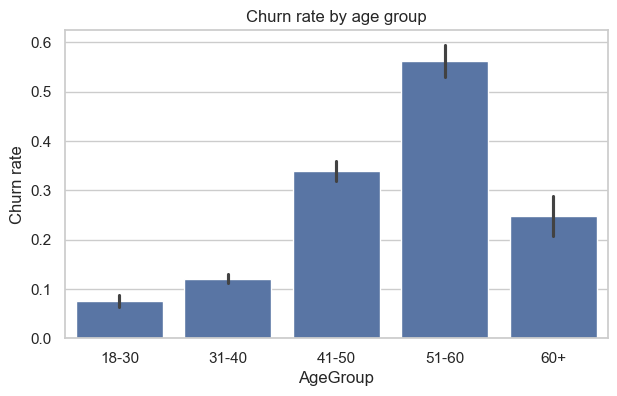

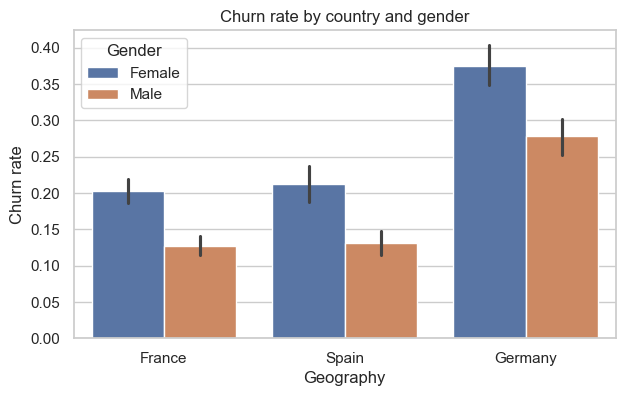

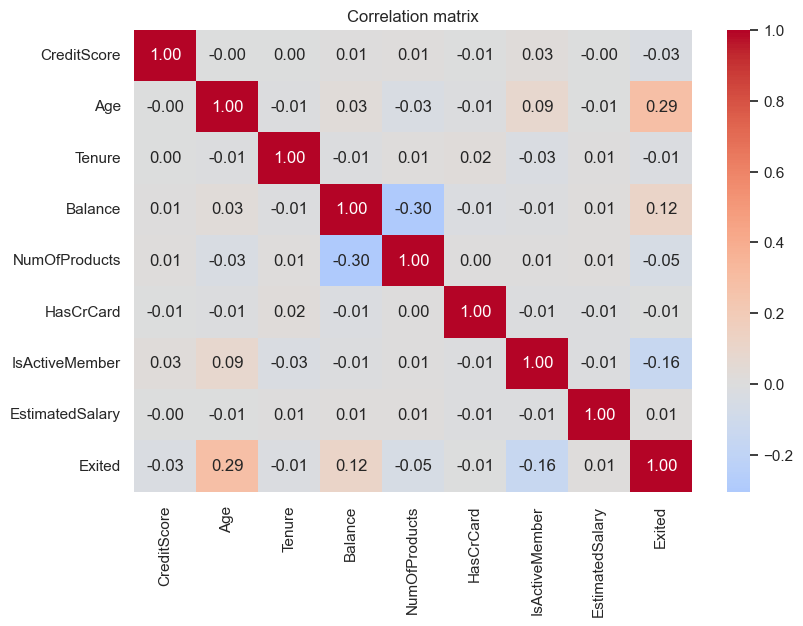

In [6]:
sns.set_theme(style="whitegrid")

num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
cat_cols = ["Geography", "Gender", "HasCrCard", "IsActiveMember", "NumOfProducts"]

# 1. Churn distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Exited", data=df, ax=ax[0])
ax[0].set_title("Churn count")
df["Exited"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1], labels=["Stayed", "Churned"])
ax[1].set_ylabel("")
ax[1].set_title("Churn share")
plt.tight_layout()
plt.show()

# 2. Numeric distributions (histograms split by churn)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, hue="Exited", kde=True, bins=30, ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

# 3. Boxplots: spot outliers and differences between groups
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x="Exited", y=col, data=df, ax=ax)
    ax.set_title(f"{col} vs churn")
plt.tight_layout()
plt.show()

# 4. Churn rate by category
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)["Exited"].mean().reset_index()
    sns.barplot(x=col, y="Exited", data=rate, ax=ax)
    ax.set_ylabel("Churn rate")
    ax.set_title(f"Churn rate by {col}")
axes.flat[-1].axis("off")  # hide the empty 6th panel
plt.tight_layout()
plt.show()

# 5. Age bands vs churn (age is a strong driver in this dataset)
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100],
                        labels=["18-30", "31-40", "41-50", "51-60", "60+"])
plt.figure(figsize=(7, 4))
sns.barplot(x="AgeGroup", y="Exited", data=df, order=["18-30", "31-40", "41-50", "51-60", "60+"])
plt.ylabel("Churn rate")
plt.title("Churn rate by age group")
plt.show()

# 6. Geography x Gender
plt.figure(figsize=(7, 4))
sns.barplot(x="Geography", y="Exited", hue="Gender", data=df)
plt.ylabel("Churn rate")
plt.title("Churn rate by country and gender")
plt.show()

# 7. Correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.drop(columns="AgeGroup").corr(numeric_only=True),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [7]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100],
                        labels=["18-30", "31-40", "41-50", "51-60", "60+"])

summary = df.groupby("AgeGroup", observed=True)["Exited"].agg(["count", "mean"])
summary.columns = ["customers", "churn_rate"]
print(summary.round(3))

print("\nOldest ages:", df["Age"].nlargest(10).tolist())
print("Age > 70:", (df["Age"] > 70).sum())

          customers  churn_rate
AgeGroup                       
18-30          1968       0.075
31-40          4451       0.121
41-50          2320       0.340
51-60           797       0.562
60+             464       0.248

Oldest ages: [92, 92, 88, 85, 84, 84, 83, 82, 81, 81]
Age > 70: 133


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

# ---------- Load ----------
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "raw" / "Churn_Modelling.csv")

# ---------- Prepare ----------
df = df.drop(columns=["RowNumber", "CustomerId", "Surname"], errors="ignore")
X = pd.get_dummies(df.drop(columns="Exited"), columns=["Geography", "Gender"], drop_first=True)
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

# ---------- Models ----------
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                                    max_depth=3, random_state=42),
}

# ---------- Cross-validation (more reliable than one split) ----------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, m in models.items():
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:18s} CV ROC-AUC: {scores.mean():.3f} (+/- {scores.std():.3f})")

# ---------- Fit + evaluate on the test set ----------
results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = (m, proba)
    print(f"\n===== {name} =====")
    print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

# ---------- Plots ----------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, (m, proba)) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.5).astype(int),
                                            display_labels=["Stayed", "Churned"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, (m, proba) in results.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves")
plt.show()

# ---------- Feature importance (Random Forest) ----------
rf = results["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(7, 5))
plt.title("Random Forest feature importance")
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'sklearn'